# Exploratory Data Analysis

In [72]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_parquet(r"C:\Users\path\to\steam_games_clean.parquet")

In [74]:
df

,app_id,name,release_date,price,price_status,estimated_owners,developers,publishers,positive,negative,...,windows,mac,linux,genres,categories,tags,copiesSold,earlyAccess,publisherClass,reviewScore
0,922630,Mortal Royale,2018-12-17,0.00,free,50000 - 100000,"[""Star Vault AB""]","[""Star Vault AB""]",99,149,...,True,False,False,"[Action, Free To Play, Early Access]","[Multi-player, PvP, Online PvP]","[Free to Play, Nudity, Violent, Action, Gore, ...",32391,True,Indie,40.0
1,922650,Caveman Chuck,2018-09-20,4.99,paid,0 - 20000,"[""Prime Bit Games SA""]","[""Prime Bit Games SA""]",19,1,...,True,False,False,"[Action, Adventure]","[Single-player, Partial Controller Support, Fa...","[Platformer, 2D, Dinosaurs, Retro, Indie, Acti...",428,False,Indie,95.0
2,922700,Hidden Animals: Photo Hunt - Worldwide Safari,2018-10-18,2.99,paid,0 - 20000,"[""Crisp App Studio""]","[""Crisp App Studio""]",82,8,...,True,True,False,"[Adventure, Casual, Indie]","[Single-player, Steam Achievements, Steam Trad...","[Indie, Adventure, Casual, Hidden Object, Rela...",3749,False,Indie,91.0
3,922710,Knightin'+,2019-07-26,5.99,paid,20000 - 50000,"[""Muzt Die Studios""]","[""Muzt Die Studios""]",232,38,...,True,True,True,"[Action, Adventure, Indie]","[Single-player, Steam Achievements, Full contr...","[Indie, Action, Adventure, Retro, Pixel Graphi...",9873,False,Indie,85.0
4,922810,MeatPossible: Chapter 1.5,2018-09-19,3.99,paid,0 - 20000,"[""Common Visual Entertainment""]","[""Common Visual Entertainment""]",15,17,...,True,True,True,"[Action, Adventure, Indie]","[Single-player, Steam Achievements, Full contr...","[Action, Indie, Adventure]",649,False,Hobbyist,48.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
128589,4636770,Bloomy Ladies,2026-05-11,8.35,paid,"0 .. 20,000","[""Pinky Cappuccino""]","[""Pinky Cappuccino""]",0,0,...,True,False,False,[Casual],"[Single-player, Steam Achievements, Family Sha...",[],76,False,Hobbyist,50.0
128590,4643580,CYBERSEX,2026-05-15,16.75,paid,"0 .. 20,000","[""SWEET LIPS Publishing""]","[""SWEET LIPS Publishing""]",0,0,...,True,False,False,"[Action, Adventure, Casual, Indie, RPG, Simula...","[Single-player, Steam Achievements, Family Sha...",[],292,False,Hobbyist,100.0
128591,4655100,A Mystic Journey With : Olea,2026-05-15,12.49,paid,"0 .. 20,000","[""Hentai Panda""]","[""Hentai Panda""]",0,0,...,True,False,False,"[Casual, Indie]","[Single-player, Steam Achievements, Camera Com...",[],27,False,Indie,100.0
128592,4674730,Hentai Clicker: Raven is streaming,2026-05-17,12.49,paid,"0 .. 20,000","[""Sexy Baguette Studio""]","[""Sexy Baguette Studio""]",0,0,...,True,True,True,"[Casual, Indie]","[Single-player, Steam Achievements, Family Sha...",[],347,False,Indie,100.0


### Move the copiesSold column after the price column:

In [75]:
copies_sold = df.pop('copiesSold') # removes copiesSold from df and temporarily stores it in copies_sold

price_position = df.columns.get_loc('price') # finds the position of the price column.

df.insert(price_position + 1, 'copiesSold', copies_sold) # puts copiesSold one position after price

### Examine the data

In [76]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 128594 entries, 0 to 128593
Data columns (total 30 columns):
 #   Column                    Non-Null Count   Dtype         
---  ------                    --------------   -----         
 0   app_id                    128594 non-null  int64         
 1   name                      128593 non-null  str           
 2   release_date              128559 non-null  datetime64[us]
 3   price                     128434 non-null  float64       
 4   copiesSold                128594 non-null  int64         
 5   price_status              128594 non-null  str           
 6   estimated_owners          128594 non-null  str           
 7   developers                128594 non-null  str           
 8   publishers                128594 non-null  str           
 9   positive                  128594 non-null  int64         
 10  negative                  128594 non-null  int64         
 11  recommendations           95728 non-null   float64       
 12  peak_ccu     

In [77]:
df.describe()

,app_id,release_date,price,copiesSold,positive,negative,recommendations,peak_ccu,metacritic_score,user_score,average_playtime_forever,median_playtime_forever,average_playtime_2weeks,median_playtime_2weeks,achievements,dlc_count,reviewScore
count,1.285940e+05,128559,128434.000000,1.285940e+05,1.285940e+05,1.285940e+05,9.572800e+04,1.285940e+05,88732.000000,128594.000000,128594.000000,128594.000000,128594.000000,128594.000000,111698.000000,128594.000000,128594.000000
mean,2.237198e+06,2022-07-26 16:19:51.571185,9.538957,6.768447e+04,9.333446e+02,1.496953e+02,1.142273e+03,4.902955e+01,3.433474,0.022692,75.816321,68.354737,6.446584,6.872342,22.228276,0.474758,72.152931
min,1.000000e+01,1997-06-30 00:00:00,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1.144335e+06,2020-05-26 00:00:00,1.990000,7.500000e+01,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,61.000000
50%,2.116765e+06,2023-06-13 00:00:00,4.990000,5.440000e+02,3.000000e+00,1.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,9.000000,0.000000,81.000000
75%,3.237605e+06,2025-05-20 00:00:00,9.990000,3.845000e+03,3.000000e+01,8.000000e+00,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,23.000000,0.000000,94.000000
max,5.180470e+06,2026-09-11 00:00:00,107500.000000,3.573578e+08,7.642084e+06,1.173003e+06,5.179195e+06,1.013936e+06,97.000000,100.000000,359665.000000,359674.000000,20014.000000,20014.000000,10979.000000,3703.000000,100.000000
std,1.287093e+06,NaN,426.754021,1.534956e+06,2.674332e+04,5.170531e+03,2.350438e+04,3.622442e+03,15.710140,1.349484,1934.023251,1916.022431,156.184395,171.562633,157.120411,11.488262,29.021610


In [78]:
df.isnull().sum()

app_id                          0
name                            1
release_date                   35
price                         160
copiesSold                      0
price_status                    0
estimated_owners                0
developers                      0
publishers                      0
positive                        0
negative                        0
recommendations             32866
peak_ccu                        0
metacritic_score            39862
user_score                      0
average_playtime_forever        0
median_playtime_forever         0
average_playtime_2weeks         0
median_playtime_2weeks          0
achievements                16896
dlc_count                       0
windows                         0
mac                             0
linux                           0
genres                          0
categories                      0
tags                            0
earlyAccess                     0
publisherClass                  0
reviewScore   

In [79]:
df.sort_values(by="copiesSold", ascending= False).head(10)

,app_id,name,release_date,price,copiesSold,price_status,estimated_owners,developers,publishers,positive,...,dlc_count,windows,mac,linux,genres,categories,tags,earlyAccess,publisherClass,reviewScore
124548,730,Counter-Strike 2,2012-08-21,0.00,357357808,free,"100,000,000 .. 200,000,000","[""Valve""]","[""Valve""]",7642084,...,1,True,False,True,"[Action, Free To Play]","[Multi-player, Cross-Platform Multiplayer, Ste...",[],False,AAA,86.0
124545,570,Dota 2,2013-07-09,0.00,228119411,free,"100,000,000 .. 200,000,000","[""Valve""]","[""Valve""]",2037143,...,2,True,True,True,"[Action, Strategy, Free To Play]","[Multi-player, Co-op, Steam Trading Cards, Ste...",[],False,AAA,81.0
94697,578080,PUBG: BATTLEGROUNDS,2017-12-21,0.00,186881996,free,"100,000,000 .. 200,000,000","[""PUBG Corporation""]","[""KRAFTON, Inc.""]",1520457,...,0,True,False,False,"[Action, Adventure, Massively Multiplayer, Fre...","[Multi-player, PvP, Online PvP, Custom Volume ...",[],False,AAA,61.0
124542,440,Team Fortress 2,2007-10-10,0.00,106051764,free,"50,000,000 .. 100,000,000","[""Valve""]","[""Valve""]",1044264,...,1,True,False,True,"[Action, Free To Play]","[Multi-player, Cross-Platform Multiplayer, Ste...",[],False,AAA,91.0
8441,1172470,Apex Legends™,2020-11-04,0.00,80963293,free,100000000 - 200000000,"[""Respawn""]","[""Electronic Arts""]",668053,...,0,True,False,False,"[Action, Adventure, Free To Play]","[Multi-player, PvP, Online PvP, Co-op, Online ...","[Free to Play, Battle Royale, Multiplayer, FPS...",False,AAA,68.0
124544,550,Left 4 Dead 2,2009-11-16,9.99,69328883,paid,"50,000,000 .. 100,000,000","[""Valve""]","[""Valve""]",940221,...,0,True,False,True,[Action],"[Single-player, Multi-player, PvP, Online PvP,...",[],False,AAA,98.0
27858,1782210,Crab Game,2021-10-29,0.00,54626507,free,5000000 - 10000000,"[""Dani""]","[""Dani""]",139538,...,0,True,True,True,"[Action, Casual, Free To Play, Indie, Racing]","[Multi-player, PvP, Online PvP, Co-op, Online ...","[Psychological Horror, Multiplayer, Free to Pl...",False,Indie,91.0
109927,304930,Unturned,2017-07-07,0.00,53058346,free,"50,000,000 .. 100,000,000","[""Smartly Dressed Games""]","[""Smartly Dressed Games""]",506516,...,1,True,True,True,"[Action, Adventure, Casual, Indie, Free To Play]","[Single-player, Multi-player, PvP, Online PvP,...",[],False,Indie,91.0
114016,230410,Warframe,2013-03-25,0.00,48905769,free,"20,000,000 .. 50,000,000","[""Digital Extremes""]","[""Digital Extremes""]",545393,...,20,True,False,False,"[Action, RPG, Free To Play]","[Single-player, Multi-player, Co-op, Online Co...",[],False,AAA,88.0
111199,236390,War Thunder,2013-08-15,0.00,40424321,free,"20,000,000 .. 50,000,000","[""Gaijin Entertainment""]","[""Gaijin Network Ltd""]",484469,...,35,True,True,True,"[Action, Massively Multiplayer, Simulation, Fr...","[Single-player, Multi-player, MMO, PvP, Online...",[],False,AAA,71.0


### Correlation table, only for numeric values:

In [80]:
df.corr(numeric_only=True)

,app_id,price,copiesSold,positive,negative,recommendations,peak_ccu,metacritic_score,user_score,average_playtime_forever,median_playtime_forever,average_playtime_2weeks,median_playtime_2weeks,achievements,dlc_count,windows,mac,linux,earlyAccess,reviewScore
app_id,1.000000,0.006134,-0.044184,-0.041073,-0.032698,-0.060896,-0.013848,-0.357600,-0.018525,-0.013036,-0.010042,-0.006747,-0.006750,-0.062125,-0.023010,-0.007521,-0.126765,-0.071585,0.029318,-0.029231
price,0.006134,1.000000,0.000610,0.000921,0.000700,0.053831,0.000238,0.154547,-0.000114,0.000741,0.000668,0.001138,0.001097,0.000394,0.000673,0.000101,0.010233,0.011591,-0.000805,0.003276
copiesSold,-0.044184,0.000610,1.000000,0.895466,0.877920,0.773568,0.881403,0.168751,-0.000498,0.016583,0.004395,0.043621,0.030611,0.015635,0.024398,0.000703,0.016597,0.020765,-0.006714,0.018246
positive,-0.041073,0.000921,0.895466,1.000000,0.816747,0.937347,0.855894,0.203421,-0.000531,0.014068,0.005571,0.024960,0.015971,0.012976,0.023670,0.000557,0.015657,0.019650,-0.005967,0.018446
negative,-0.032698,0.000700,0.877920,0.816747,1.000000,0.764525,0.838907,0.136031,-0.000413,0.016450,0.004759,0.025314,0.015366,0.009321,0.022207,0.000457,0.005238,0.008412,-0.004503,0.004651
recommendations,-0.060896,0.053831,0.773568,0.937347,0.764525,1.000000,0.716767,0.223344,-0.000526,0.016626,0.007774,0.029597,0.019001,0.021147,0.026519,0.000666,0.020187,0.021170,-0.005018,0.023315
peak_ccu,-0.013848,0.000238,0.881403,0.855894,0.838907,0.716767,1.000000,0.056538,-0.000222,0.016809,0.003808,0.034895,0.021225,0.004442,0.008205,0.000217,0.005109,0.010069,-0.002215,0.005127
metacritic_score,-0.357600,0.154547,0.168751,0.203421,0.136031,0.223344,0.056538,1.000000,0.001630,0.009117,0.003306,0.023871,0.022717,0.191488,0.034100,0.003113,0.128766,0.091021,-0.067883,0.065227
user_score,-0.018525,-0.000114,-0.000498,-0.000531,-0.000413,-0.000526,-0.000222,0.001630,1.000000,0.000030,0.000135,-0.000694,-0.000674,0.001698,0.000533,0.000269,0.003450,0.005450,-0.005431,0.002175
average_playtime_forever,-0.013036,0.000741,0.016583,0.014068,0.016450,0.016626,0.016809,0.009117,0.000030,1.000000,0.934509,0.241857,0.234696,0.004741,0.018749,0.000628,0.003056,-0.005975,-0.003533,0.013296


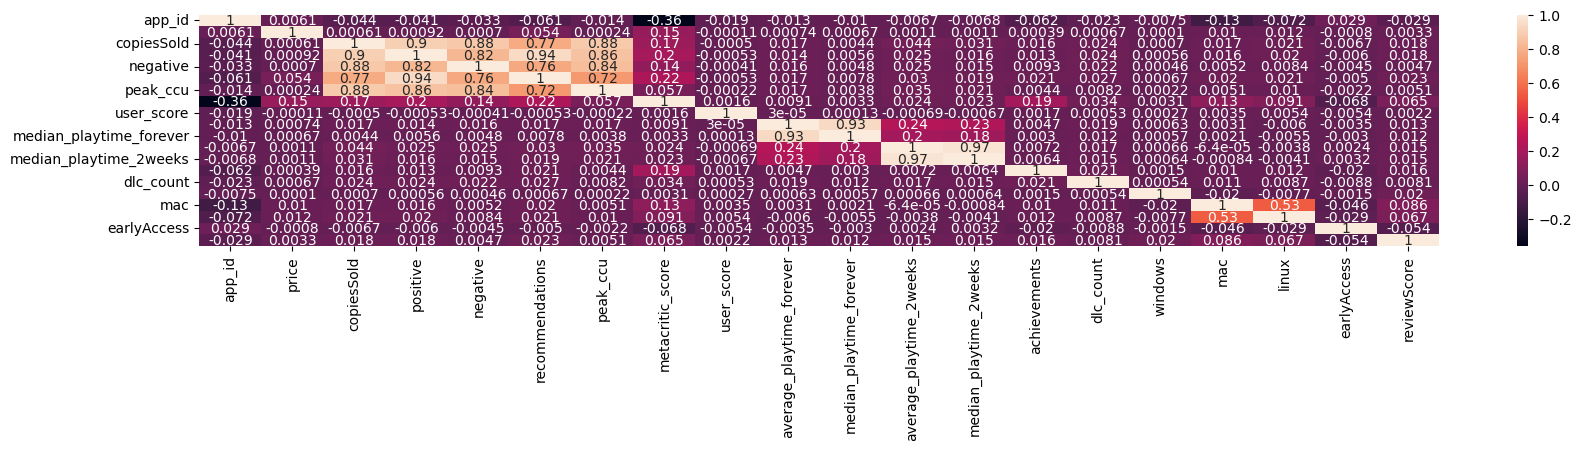

In [81]:
sns.heatmap(df.corr(numeric_only=True), annot = True)
plt.rcParams['figure.figsize'] = (20,3)
plt.show()

In [82]:
df.groupby('publisherClass').mean(numeric_only=True).sort_values(by="copiesSold", ascending= False)

,app_id,price,copiesSold,positive,negative,recommendations,peak_ccu,metacritic_score,user_score,average_playtime_forever,median_playtime_forever,average_playtime_2weeks,median_playtime_2weeks,achievements,dlc_count,windows,mac,linux,earlyAccess,reviewScore
publisherClass,,,,,,,,,,,,,,,,,,,,
AAA,1.031983e+06,26.580830,2.426064e+06,38790.683748,7176.614934,34404.157044,3019.543924,48.825099,0.000000,535.194729,278.292826,97.034407,99.956076,48.669829,4.491215,1.000000,0.108346,0.079063,0.012445,77.855783
AA,1.346534e+06,19.359042,6.076905e+05,9435.029089,1130.621332,10644.283880,328.891554,29.099343,0.022200,356.682827,299.396275,42.682062,46.985200,36.253410,2.422302,1.000000,0.182955,0.109722,0.039806,78.171217
Indie,1.888975e+06,14.698720,5.370212e+04,554.278937,91.166226,686.377910,16.621548,5.019215,0.045191,148.643246,140.440469,10.348055,11.016155,33.961857,0.673505,0.999961,0.243392,0.173209,0.068112,75.926543
Hobbyist,2.551059e+06,5.092319,3.935822e+03,26.976395,5.425984,3.839391,0.669811,0.118148,0.007437,1.170452,1.607935,0.062895,0.063239,12.591870,0.155330,0.999573,0.138873,0.114759,0.117362,69.086224


In [83]:
df2 = df.groupby('publisherClass')[['price', 'copiesSold', 'recommendations', 'reviewScore']].mean(numeric_only=True).sort_values(by="copiesSold", ascending= False)
df2

,price,copiesSold,recommendations,reviewScore
publisherClass,,,,
AAA,26.580830,2.426064e+06,34404.157044,77.855783
AA,19.359042,6.076905e+05,10644.283880,78.171217
Indie,14.698720,5.370212e+04,686.377910,75.926543
Hobbyist,5.092319,3.935822e+03,3.839391,69.086224


In [96]:
# for this output, the plot is not useful.

# df3 = df2.transpose()
# df3.plot()

In [85]:
df.groupby('price_status')[['price', 'copiesSold', 'recommendations', 'reviewScore']].mean(numeric_only=True).sort_values(by="copiesSold", ascending= False)

,price,copiesSold,recommendations,reviewScore
price_status,,,,
free,0.001381,175437.003472,725.058384,77.541035
paid,11.282511,51390.968411,1207.109304,71.600157
unavailable,7.143211,20339.325270,5856.902439,64.262695


### Add number of games per price status:

In [86]:
df4 = df.groupby('price_status').agg(
    number_of_games=('app_id', 'count'),
    average_price=('price', 'mean'),
    average_copies_sold=('copiesSold', 'mean'),
    average_recommendations=('recommendations', 'mean'),
    average_review_score=('reviewScore', 'mean')
).sort_values(
    by='average_copies_sold',
    ascending=False
)
df4

,number_of_games,average_price,average_copies_sold,average_recommendations,average_review_score
price_status,,,,,
free,18143,0.001381,175437.003472,725.058384,77.541035
paid,105449,11.282511,51390.968411,1207.109304,71.600157
unavailable,5002,7.143211,20339.325270,5856.902439,64.262695


### In this plot we can see better that we have way more paid games, but the copies of the games sold is way lower compared to free games, which makes sense.

<Axes: >

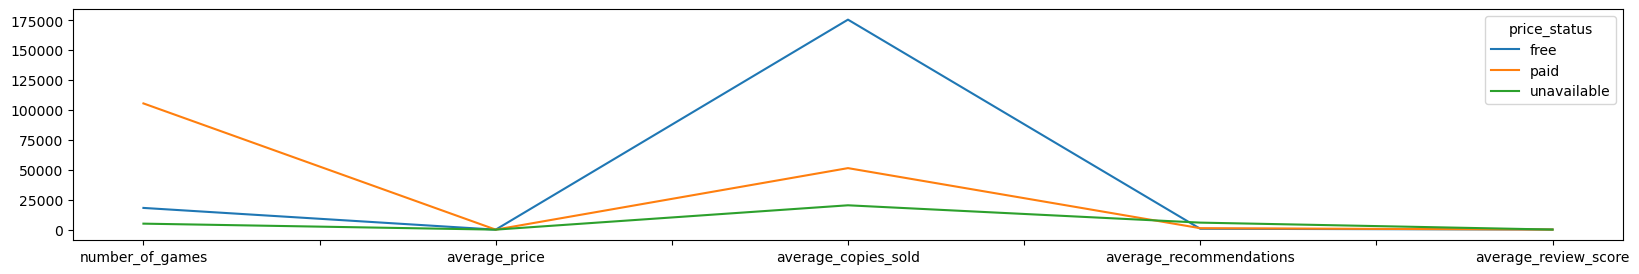

In [87]:
df5 = df4.transpose()
df5.plot()

### See outliers

<Axes: >

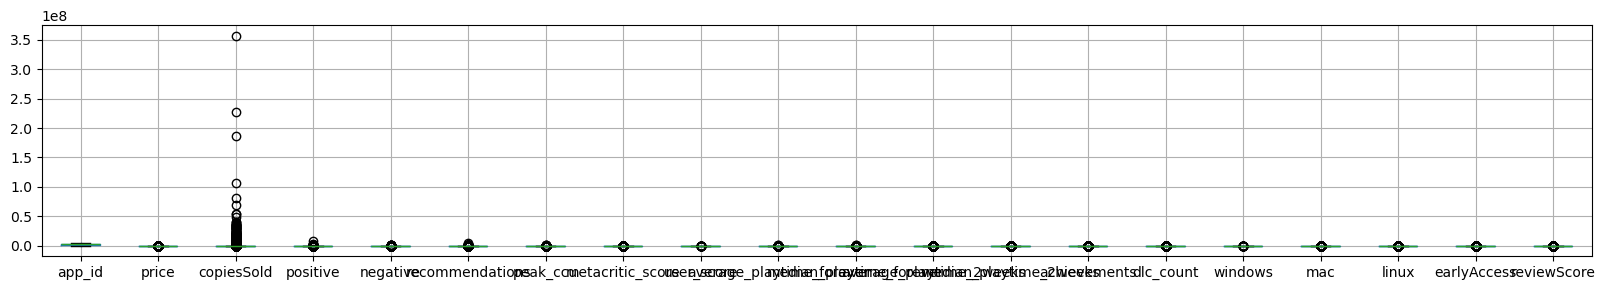

In [ ]:
df.boxplot() # need to look at specific values

<Axes: >

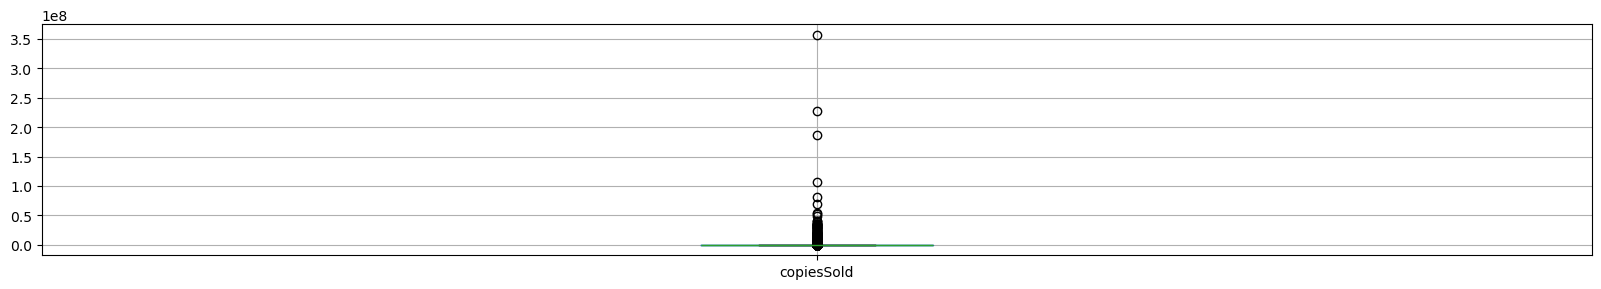

In [89]:
df.boxplot(column='copiesSold')

<Axes: >

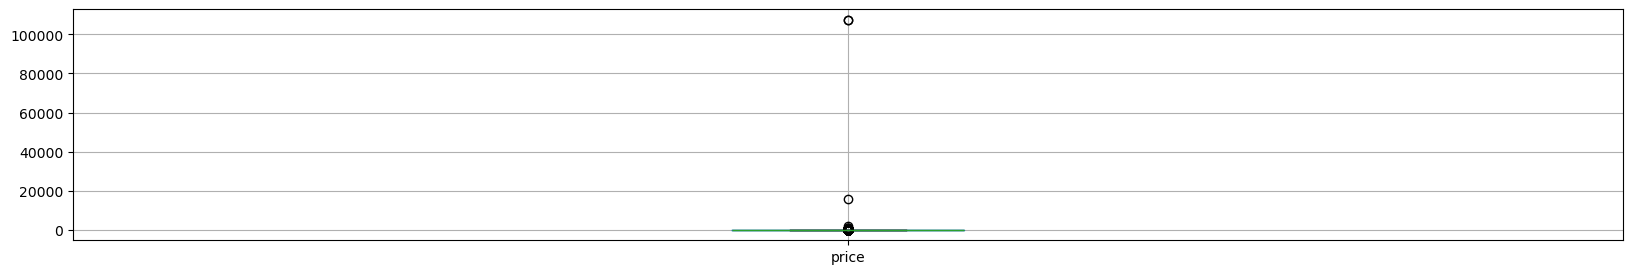

In [90]:
df.boxplot(column='price')

### Number of games per publisher class:

In [93]:
df['publisherClass'].value_counts()

publisherClass
Hobbyist    72613
Indie       50696
AA           3919
AAA          1366
Name: count, dtype: int64

In [94]:
df['price_status'].value_counts()

price_status
paid           105449
free            18143
unavailable      5002
Name: count, dtype: int64

### Top 10 genres

In [97]:
df['genres'].explode().value_counts().head(10)

genres
Indie           92445
Casual          58111
Action          51488
Adventure       50281
Simulation      28223
Strategy        26217
RPG             23696
Free To Play    13868
Early Access    12656
Sports           5358
Name: count, dtype: int64

### Top 10 categories

In [98]:
df['categories'].explode().value_counts().head(10)

categories
Single-player                   123397
Family Sharing                  113553
Steam Achievements               64817
Steam Cloud                      36444
Full controller support          29142
Multi-player                     22805
Partial Controller Support       14649
Playable without Timed Input     14374
PvP                              14120
Custom Volume Controls           13888
Name: count, dtype: int64

### Top 10 tags

In [103]:
df['tags'].explode().value_counts().head(10)

tags
Singleplayer    40376
Indie           30771
Casual          26060
Action          24450
Adventure       24361
2D              21723
3D              16596
Colorful        12472
Atmospheric     12411
Simulation      12264
Name: count, dtype: int64

### Releases over time

<Axes: xlabel='release_year'>

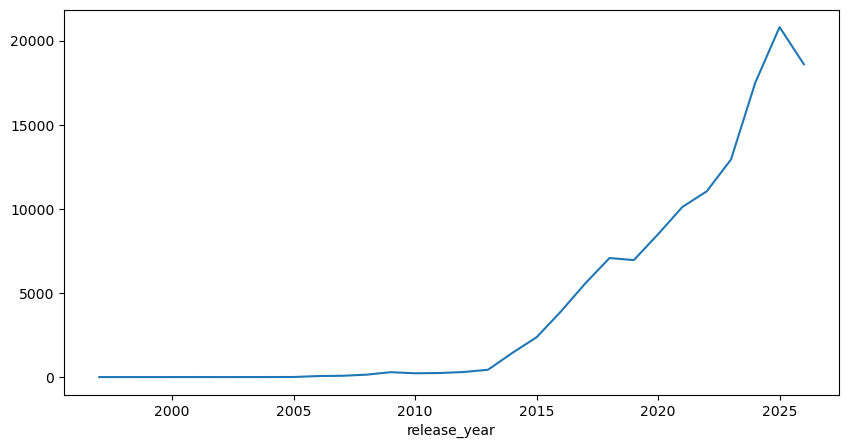

In [102]:
df['release_year'] = df['release_date'].dt.year

df['release_year'].value_counts().sort_index().plot(
    kind='line',
    figsize=(10, 5)
)